# **Data Preparation**

**Objective:** turn the raw download into three sets, train, validation and test, ready for the CNN.

**Steps:**
1. Gather the images of each class and drop exact duplicates.
2. Split them 70/10/20 with a fixed seed.
3. Balance **only the training set** with synthetic images.
4. Resize everything to 50x50 pixels.

**Why this order.** The 2024 version of this notebook generated the synthetic images before the split. A mirrored or rotated copy of a leaf could then land in the test set while its original was in training, and the test accuracy measured partly memory. Splitting first means the test set holds only original images the model never saw in any form.

In [1]:
from pathlib import Path

# The notebooks live in notebooks/; every path is relative to the repository root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "inputs" / "raw" / "cherry-leaves"
PREPARED = ROOT / "inputs" / "prepared"
OUTPUTS = ROOT / "outputs"
print("Repository root:", ROOT.name)

import hashlib
import random
import shutil

from PIL import Image, ImageEnhance, ImageOps

SEED = 42
CLASSES = ["healthy", "powdery_mildew"]
SPLIT = {"train": 0.7, "validation": 0.1, "test": 0.2}
SIZE = (50, 50)

Repository root: mildew


## 1. Gather each class and drop exact duplicates

Two files with the same bytes are the same image. If one went to training and the other to test, the test would be measuring memory again.

In [2]:
images = {}
for label in CLASSES:
    seen, kept, duplicates = set(), [], 0
    for path in sorted(RAW.glob(f"*/{label}/*")):
        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        if digest in seen:
            duplicates += 1
            continue
        seen.add(digest)
        kept.append(path)
    images[label] = kept
    print(f"{label}: {len(kept)} unique images, {duplicates} exact duplicates dropped")

healthy: 2282 unique images, 704 exact duplicates dropped


powdery_mildew: 2104 unique images, 689 exact duplicates dropped


## 2. Split with a fixed seed

The seed makes the split reproducible: running the notebook again gives the same three sets.

In [3]:
rng = random.Random(SEED)
sets = {name: {} for name in SPLIT}
for label, paths in images.items():
    paths = paths[:]
    rng.shuffle(paths)
    n_train = int(len(paths) * SPLIT["train"])
    n_val = int(len(paths) * SPLIT["validation"])
    sets["train"][label] = paths[:n_train]
    sets["validation"][label] = paths[n_train:n_train + n_val]
    sets["test"][label] = paths[n_train + n_val:]

for name, by_label in sets.items():
    print(name, {label: len(p) for label, p in by_label.items()})

train {'healthy': 1597, 'powdery_mildew': 1472}
validation {'healthy': 228, 'powdery_mildew': 210}
test {'healthy': 457, 'powdery_mildew': 422}


## 3. Write the sets, resized to 50x50

Due to system limitations in 2024, the images were reduced to 50x50 pixels; the rescue keeps that size so the result can be compared. The raw download is left untouched: this notebook can be run again.

In [4]:
if PREPARED.exists():
    shutil.rmtree(PREPARED)

def write(path, destination):
    destination.parent.mkdir(parents=True, exist_ok=True)
    with Image.open(path) as img:
        img.convert("RGB").resize(SIZE, Image.Resampling.LANCZOS).save(destination, quality=95)

for name, by_label in sets.items():
    for label, paths in by_label.items():
        for i, path in enumerate(paths):
            write(path, PREPARED / name / label / f"{label}_{i:04d}.jpg")
print("Sets written to", PREPARED.relative_to(ROOT))

Sets written to inputs\prepared


## 4. Balance the training set only

The smaller class gets synthetic images made from its own **training** images: a mirror, a change of brightness or a rotation, chosen at random with the same seed. Validation and test keep their natural proportions.

In [5]:
def random_transformation(image):
    choice = rng.randint(1, 3)
    if choice == 1:
        return ImageOps.mirror(image)
    if choice == 2:
        return ImageEnhance.Brightness(image).enhance(rng.uniform(0.5, 1.5))
    return image.rotate(rng.choice([90, 180, 270]))

train_counts = {label: len(p) for label, p in sets["train"].items()}
minority = min(train_counts, key=train_counts.get)
to_generate = max(train_counts.values()) - train_counts[minority]
folder = PREPARED / "train" / minority
originals = sorted(folder.iterdir())
for i in range(to_generate):
    with Image.open(rng.choice(originals)) as img:
        random_transformation(img.convert("RGB")).save(folder / f"synthetic_{i:04d}.jpg", quality=95)
print(f"{to_generate} synthetic images added to train/{minority}")

125 synthetic images added to train/powdery_mildew


## 5. Check the result

In [6]:
total = 0
for name in SPLIT:
    counts = {label: len(list((PREPARED / name / label).iterdir())) for label in CLASSES}
    total += sum(counts.values())
    print(f"{name:<10}", counts)
print("total images used:", total)

with Image.open(next((PREPARED / "test" / "healthy").iterdir())) as img:
    print("image size:", img.size)

train      {'healthy': 1597, 'powdery_mildew': 1597}
validation {'healthy': 228, 'powdery_mildew': 210}
test       {'healthy': 457, 'powdery_mildew': 422}
total images used: 4511
image size: (50, 50)


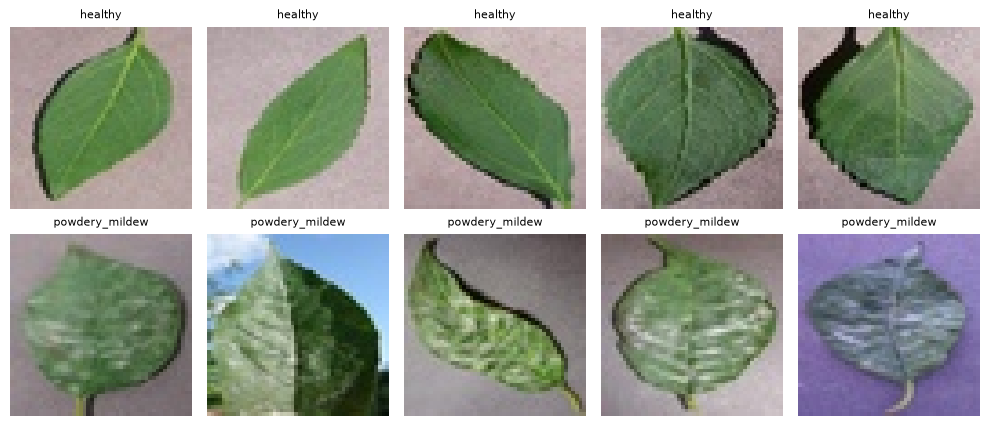

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(10, 4.4))
for row, label in enumerate(CLASSES):
    for ax, path in zip(axes[row], sorted((PREPARED / "train" / label).glob(f"{label}_*.jpg"))[:5]):
        ax.imshow(Image.open(path))
        ax.set_title(label, fontsize=8)
        ax.axis("off")
plt.tight_layout()
plt.show()